# Midterm Project: Comparing Three NLP Models

This project compares three character-level language modeling architectures: the bigram model, the LSTM model, and a small Transformer.

The goal is to predict the next character based on existing text content.

All three models were trained using the “Tiny Shakespeare” dataset. The evaluation metrics include training loss, validation loss, training time, and text samples generated by the models.

In addition, this project explores how different architectures process contextual information and analyzes the impact of the self-attention mechanism on language modeling performance.

In [2]:
import os
import time
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Choose hardware
device = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu


In [3]:
# Create directories
Path("data").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

# Dataset URL
url = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/"
    "master/data/tinyshakespeare/input.txt"
)

data_path = Path("data/input.txt")

# Download if necessary
if not data_path.exists():
    urllib.request.urlretrieve(url, data_path)

# Load text
text = data_path.read_text(encoding="utf-8")

print("Total characters:", len(text))
print("\nFirst 500 characters:")
print(text[:500])

Total characters: 1115394

First 500 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


# Dataset Description
This project uses the “Tiny Shakespeare” dataset, which contains about 1.1 million characters from Shakespeare’s plays.

This dataset is used for the “character-based next-character prediction” task. Each unique character has been converted into a numerical token.

The data is split into a 90% training set and a 10% validation set.
All three models use the same dataset and vocabulary to ensure a fair comparison.

In [4]:
# Build character vocabulary
chars = sorted(set(text))

vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s):
    return [stoi[c] for c in s]

def decode(indices):
    return "".join(itos[int(i)] for i in indices)

# Encode dataset
data = torch.tensor(encode(text), dtype=torch.long)

# Train/validation split
n = int(0.9 * len(data))

train_data = data[:n]
val_data = data[n:]

print("Vocabulary size:", vocab_size)
print("Training characters:", len(train_data))
print("Validation characters:", len(val_data))

print("Example encoding:", encode("Hello"))
print("Example decoding:", decode(encode("Hello")))

Vocabulary size: 65
Training characters: 1003854
Validation characters: 111540
Example encoding: [20, 43, 50, 50, 53]
Example decoding: Hello


In [5]:
# Shared training settings
BATCH_SIZE = 32
BLOCK_SIZE = 64

MAX_STEPS = 600
EVAL_INTERVAL = 150
EVAL_BATCHES = 10

LEARNING_RATE = 0.003

# Model settings
EMBED_DIM = 64
HIDDEN_DIM = 128

NUM_HEADS = 4
NUM_LAYERS = 2
DROPOUT = 0.1

def get_batch(split, generator):
    source = train_data if split == "train" else val_data

    starts = torch.randint(
        0,
        len(source) - BLOCK_SIZE,
        (BATCH_SIZE,),
        generator=generator
    )

    x = torch.stack([
        source[i:i + BLOCK_SIZE]
        for i in starts.tolist()
    ])

    y = torch.stack([
        source[i + 1:i + BLOCK_SIZE + 1]
        for i in starts.tolist()
    ])

    return x.to(device), y.to(device)

# Check batch dimensions
test_generator = torch.Generator().manual_seed(SEED)
xb, yb = get_batch("train", test_generator)

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

print("\nInput example:")
print(decode(xb[0].cpu().tolist()))

print("\nTarget example:")
print(decode(yb[0].cpu().tolist()))

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])

Input example:
Paris!
What said my man, when my betossed soul
Did not attend hi

Target example:
aris!
What said my man, when my betossed soul
Did not attend him


# Model 1: Bigram Model
A binary model predicts the next character based only on the current character.

For each character in the vocabulary, it learns the probability of characters that might follow.

For example, after observing the character “q,” the model might assign a higher probability to the character “u.”

However, a binary model ignores all previous characters. It cannot effectively understand vocabulary, syntax, or long-range dependencies.

This model serves as a baseline for comparing more complex language models.

In [7]:
class BigramModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.table = nn.Embedding(
            vocab_size,
            vocab_size
        )

    def forward(self, idx):
        logits = self.table(idx)
        return logits

# Model 2: LSTM Model
The second model uses a LSTM model.

Unlike the bigram model, LSTM processes characters in sequence and maintains a hidden state that generalizes previous inputs.

Its memory cells and gate mechanisms enable the model to both retain and update information across multiple time steps.

This enables the LSTM to learn patterns involving multiple characters, such as common vocabulary and sentence structures.

However, LSTMs may still face difficulties when handling long-range dependencies. Information must be passed through continuous recurrent steps, so learning associations between long sequences is often challenging.

In this experiment, the context window length processed by the LSTM is 64 characters.

In [8]:
class LSTMModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            EMBED_DIM
        )

        self.lstm = nn.LSTM(
            input_size=EMBED_DIM,
            hidden_size=HIDDEN_DIM,
            batch_first=True
        )

        self.output = nn.Linear(
            HIDDEN_DIM,
            vocab_size
        )

    def forward(self, idx):

        x = self.embedding(idx)

        x, _ = self.lstm(x)

        logits = self.output(x)

        return logits

# Model 3: Small Transformer Model
The third model uses a small transformer model.

This model includes:

1. Token embeddings
2. Learned positional embeddings
3. Multi-head self-attention
4. Feedforward neural networks
5. Layer normalization and residual connections
6. Final output layer

The self-attention mechanism allows each character position to pay attention to other relevant positions within the same context window.

Unlike LSTMs, Transformers do not need to process dependencies by cycling through hidden states.

The causal attention mask prevents any position from accessing subsequent characters during the prediction process.

This allows the model to perform autoregressive “next character” predictions without having prior knowledge of the actual target character.

In [9]:
class TransformerBlock(nn.Module):

    def __init__(self):
        super().__init__()

        self.ln1 = nn.LayerNorm(EMBED_DIM)

        self.attn = nn.MultiheadAttention(
            embed_dim=EMBED_DIM,
            num_heads=NUM_HEADS,
            dropout=DROPOUT,
            batch_first=True
        )

        self.ln2 = nn.LayerNorm(EMBED_DIM)

        self.ff = nn.Sequential(
            nn.Linear(EMBED_DIM, 4 * EMBED_DIM),
            nn.GELU(),
            nn.Linear(4 * EMBED_DIM, EMBED_DIM),
            nn.Dropout(DROPOUT)
        )

    def forward(self, x):

        T = x.size(1)

        # Block attention to future positions
        causal_mask = torch.triu(
            torch.ones(
                T, T,
                device=x.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        z = self.ln1(x)

        attended, _ = self.attn(
            z, z, z,
            attn_mask=causal_mask,
            need_weights=False
        )

        # Residual connection
        x = x + attended

        # Feedforward network
        x = x + self.ff(self.ln2(x))

        return x

In [10]:
class TransformerModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()

        # Character embeddings
        self.token_embedding = nn.Embedding(
            vocab_size,
            EMBED_DIM
        )

        # Positional embeddings
        self.position_embedding = nn.Embedding(
            BLOCK_SIZE,
            EMBED_DIM
        )

        # Transformer layers
        self.blocks = nn.Sequential(
            *[
                TransformerBlock()
                for _ in range(NUM_LAYERS)
            ]
        )

        self.ln_final = nn.LayerNorm(EMBED_DIM)

        # Character prediction
        self.output = nn.Linear(
            EMBED_DIM,
            vocab_size
        )

    def forward(self, idx):

        B, T = idx.shape

        assert T <= BLOCK_SIZE

        # Token information
        token_emb = self.token_embedding(idx)

        # Position information
        positions = torch.arange(
            T,
            device=idx.device
        )

        pos_emb = self.position_embedding(positions)

        # Combine embeddings
        x = token_emb + pos_emb

        # Apply attention blocks
        x = self.blocks(x)

        x = self.ln_final(x)

        logits = self.output(x)

        return logits

# Training Method
All three models use the same training and validation sets.

Model training employs the AdamW optimizer and the cross-entropy loss function.

The number of optimization steps and the sampling order of training batch sizes were maintained consistently across all models.

Both training and validation losses were evaluated using fixed, identical batches to enable direct comparison of results.

Training duration was recorded as actual wall-clock time, which included the time required for scheduled evaluations.

The number of parameters and computational requirements differed across models. These factors were taken into account when analyzing the results.

In [11]:
def calculate_loss(model, x, y):

    logits = model(x)

    loss = F.cross_entropy(
        logits.reshape(-1, vocab_size),
        y.reshape(-1)
    )

    return loss


# Create identical evaluation batches for all models
def make_fixed_batches(split, count, seed):

    generator = torch.Generator().manual_seed(seed)

    return [
        get_batch(split, generator)
        for _ in range(count)
    ]


fixed_eval = {
    "train": make_fixed_batches(
        "train", EVAL_BATCHES, SEED + 200
    ),
    "val": make_fixed_batches(
        "val", EVAL_BATCHES, SEED + 300
    )
}


@torch.no_grad()
def evaluate(model):

    model.eval()

    results = {}

    for split in ["train", "val"]:

        losses = []

        for x, y in fixed_eval[split]:
            loss = calculate_loss(model, x, y)
            losses.append(loss.item())

        results[split] = np.mean(losses)

    model.train()

    return results

In [12]:
def train_model(name, model):

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    # Reset batch generator for fair comparison
    generator = torch.Generator().manual_seed(
        SEED + 100
    )

    history = []

    if device == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for step in range(MAX_STEPS):

        xb, yb = get_batch("train", generator)

        loss = calculate_loss(model, xb, yb)

        optimizer.zero_grad(set_to_none=True)

        loss.backward()

        optimizer.step()

        # Evaluate at regular intervals
        if (
            (step + 1) % EVAL_INTERVAL == 0
            or step == MAX_STEPS - 1
        ):

            scores = evaluate(model)

            history.append({
                "step": step + 1,
                "train_loss": scores["train"],
                "validation_loss": scores["val"]
            })

            print(
                f"{name} | "
                f"Step {step + 1} | "
                f"Train Loss: {scores['train']:.4f} | "
                f"Val Loss: {scores['val']:.4f}"
            )

    if device == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time

    print(
        f"\n{name} completed in "
        f"{elapsed:.2f} seconds.\n"
    )

    return {
        "model": model,
        "history": history,
        "train_loss": history[-1]["train_loss"],
        "validation_loss": history[-1]["validation_loss"],
        "train_seconds": elapsed
    }

In [13]:
model_classes = {
    "Bigram": BigramModel,
    "LSTM": LSTMModel,
    "Transformer": TransformerModel
}

results = {}

for name, model_class in model_classes.items():

    print("=" * 55)
    print("Training:", name)
    print("=" * 55)

    torch.manual_seed(SEED)

    model = model_class(vocab_size)

    results[name] = train_model(name, model)

print("\nAll models finished training.")

Training: Bigram
Bigram | Step 150 | Train Loss: 4.1852 | Val Loss: 4.1957
Bigram | Step 300 | Train Loss: 3.7198 | Val Loss: 3.7393
Bigram | Step 450 | Train Loss: 3.3632 | Val Loss: 3.3876
Bigram | Step 600 | Train Loss: 3.0983 | Val Loss: 3.1253

Bigram completed in 0.49 seconds.

Training: LSTM
LSTM | Step 150 | Train Loss: 2.1090 | Val Loss: 2.1504
LSTM | Step 300 | Train Loss: 1.9135 | Val Loss: 2.0017
LSTM | Step 450 | Train Loss: 1.8081 | Val Loss: 1.9238
LSTM | Step 600 | Train Loss: 1.7402 | Val Loss: 1.8712

LSTM completed in 6.10 seconds.

Training: Transformer
Transformer | Step 150 | Train Loss: 2.4184 | Val Loss: 2.4516
Transformer | Step 300 | Train Loss: 2.1868 | Val Loss: 2.2268
Transformer | Step 450 | Train Loss: 2.0602 | Val Loss: 2.1275
Transformer | Step 600 | Train Loss: 1.9646 | Val Loss: 2.0560

Transformer completed in 21.75 seconds.


All models finished training.


# Text Generation
After training, each model generates text using an auto-regressive approach.

All three models receive the same initial prompt.

At each step, the model predicts the probability distribution of the next character, samples a character from it, and appends it to the end of the sequence.

To ensure equal conditions for qualitative comparison, all models used the same sampling temperature and generation length.

The generated samples were evaluated based on their vocabulary, readability, grammatical patterns, and consistency.

In [14]:
@torch.no_grad()
def generate_text(
    model,
    prompt,
    max_new_tokens=300,
    temperature=0.8
):

    model.eval()

    idx = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    for _ in range(max_new_tokens):

        # Use the latest context window
        idx_cond = idx[:, -BLOCK_SIZE:]

        logits = model(idx_cond)

        # Predict using final position
        logits = logits[:, -1, :]

        logits = logits / temperature

        probs = F.softmax(logits, dim=-1)

        next_id = torch.multinomial(
            probs,
            num_samples=1
        )

        idx = torch.cat(
            [idx, next_id],
            dim=1
        )

    return decode(idx[0].cpu().tolist())

In [15]:
PROMPT = "ROMEO:\n"

generated_samples = {}

for name, result in results.items():

    torch.manual_seed(2026)

    sample = generate_text(
        model=result["model"],
        prompt=PROMPT,
        max_new_tokens=300,
        temperature=0.8
    )

    generated_samples[name] = sample

    print("\n" + "=" * 50)
    print(name, "Generated Text")
    print("=" * 50)

    print(sample)


# Save all generated samples
with open(
    "results/generated_samples.txt",
    "w",
    encoding="utf-8"
) as f:

    for name, sample in generated_samples.items():

        f.write(f"\n{'=' * 50}\n")
        f.write(f"{name}\n")
        f.write(f"{'=' * 50}\n\n")

        f.write(sample + "\n")

print("\nGenerated samples saved.")


Bigram Generated Text
ROMEO:

FiQatrGByZ3WhewUp'd wjasiradVF-maHasl d pase mK: sprip eg'cykis


MET'tonYOVzetDWhjvirot taPawancheIS?wheryRY trou moo ,Y'smaTEF&IvKGYe mo'InevCJvTho clfivUr lwqu IOLTquts&HkbozeGonarcaqut$hSIDYeptXopy$lR QBCrdaseaTwjflyosaTVIYe wan 
tD: latimantFAf
anghLYzld eman wiffleuXhor mr? I: blVAmankx-fwqjo

LSTM Generated Text
ROMEO:
And a reat lets my see as I did my as the see my fortinger's his
depeept a pellatter would and such I sweer so thee is the smay of lessee, 'I are and that were will he dous lobderoon his grace.

KING RICHARD II:
I am contasie?

AUTELY:

LUCIO:
I manfeath theld hand with enveir mister be our as your 

Transformer Generated Text
ROMEO:
And a rely leve post weas but the fas the spell the
His encenk sone came and mut the wout theakence.

PORYCURYCOMABUTENTEY:
I, more, have re not with of tis dear and promest king ooker:
And his contropell neess as and fleasid?

FRYCENTHENTENINI:
My faand thild har my foreever wir?

RISARY:
I show so

Gen

# Model Comparison
These three models were evaluated based on the following metrics:

- Training loss
- Validation loss
- Training duration
- Number of trainable parameters
- Quality of generated text

A lower cross-entropy loss reflects stronger performance in predicting the next character.

The best-performing model is primarily determined based on validation loss, while the generated text is also evaluated qualitatively.

When determining whether a performance improvement is worth the computational cost, both training duration and model complexity are collectively considered.

In [16]:
comparison_rows = []

for name, result in results.items():

    model = result["model"]

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    comparison_rows.append({
        "Model": name,
        "Train Loss": round(result["train_loss"], 4),
        "Validation Loss": round(
            result["validation_loss"], 4
        ),
        "Training Time (s)": round(
            result["train_seconds"], 2
        ),
        "Parameters": parameter_count
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

comparison_df.to_csv(
    "results/comparison.csv",
    index=False
)

,Model,Train Loss,Validation Loss,Training Time (s),Parameters
0,Bigram,3.0983,3.1253,0.49,4225
1,LSTM,1.7402,1.8712,6.10,111873
2,Transformer,1.9646,2.0560,21.75,112577


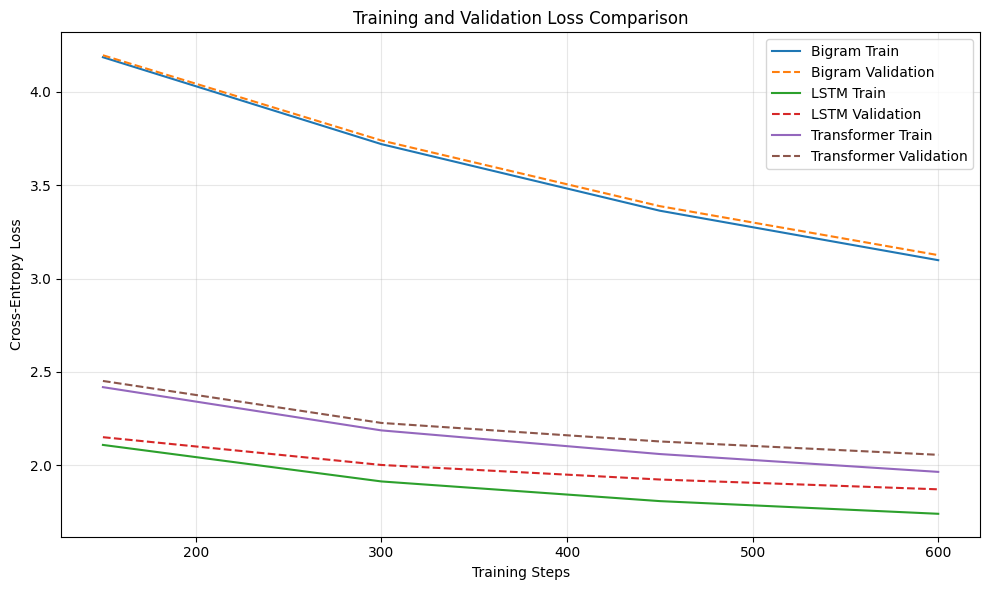

In [17]:
plt.figure(figsize=(10, 6))

for name, result in results.items():

    history = pd.DataFrame(result["history"])

    plt.plot(
        history["step"],
        history["train_loss"],
        label=f"{name} Train"
    )

    plt.plot(
        history["step"],
        history["validation_loss"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")

plt.title("Training and Validation Loss Comparison")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "results/loss_curves.png",
    dpi=300
)

plt.show()

In [18]:
# Best validation performance
best_idx = comparison_df["Validation Loss"].idxmin()

best_model = comparison_df.loc[
    best_idx, "Model"
]

# Fastest training
fastest_idx = comparison_df[
    "Training Time (s)"
].idxmin()

fastest_model = comparison_df.loc[
    fastest_idx, "Model"
]

print("Best Validation Performance:", best_model)

print("Fastest Training Model:", fastest_model)

print("\nValidation Loss Ranking:")

display(
    comparison_df.sort_values(
        "Validation Loss"
    )
)

Best Validation Performance: LSTM
Fastest Training Model: Bigram

Validation Loss Ranking:


,Model,Train Loss,Validation Loss,Training Time (s),Parameters
1,LSTM,1.7402,1.8712,6.10,111873
2,Transformer,1.9646,2.0560,21.75,112577
0,Bigram,3.0983,3.1253,0.49,4225


# Qualitative Analysis

# 1. Which model performed best?
The LSTM model performed best overall, with the lowest training loss (1.7402) and validation loss (1.8712). The Transformer model ranked second, with a validation loss of 2.0560. The Bigram model ranked last, with a validation loss of 3.1253.

Although the Transformer uses self-attention mechanisms, its performance did not exceed that of the LSTM under the current training configuration.

# 2. Which model trained fastest?
The Bigram model trains the fastest, completing 600 training steps in just 0.49 seconds. The LSTM takes 6.10 seconds, while the Transformer takes 21.75 seconds.

The Bigram model is highly computationally efficient because it contains only 4,225 parameters. The LSTM and Transformer have similar numbers of parameters (111,873 and 112,577, respectively), but the Transformer takes significantly longer to train.

# 3. Which model generated the most realistic text?
Of these three models, the LSTM generates the most realistic text.

The character sequences generated by the Bigram model mostly appear random and are nearly incapable of forming meaningful words. The LSTM, on the other hand, can generate recognizable English phrases and Shakespearean-style dialogue, even including character identifiers such as “KING RICHARD II” and “LUCIO.”

The Transformer can also generate recognizable phrases and conversational structures, but its output contains more unusual character names and incomplete words.

Overall, among the observed samples, the text generated by the LSTM is the most readable, although none of these models managed to generate fully consistent language.

# 4. What did the transformer improve compared to the other models?
Compared to the Bigram model, the Transformer shows a significant improvement in its ability to predict the next character and can generate more recognizable language patterns.

The Bigram model considers only the current character, while the Transformer utilizes an auto-attention mechanism to combine information from multiple previous positions.

Unlike LSTM, the Transformer can directly link different positions within the context window without relying on updates to the hidden recurrent state. However, in this experiment, the Transformer did not outperform the LSTM.

# 5. Was the improvement worth the added complexity?
Under the current experimental setup, the added complexity of the Transformer did not result in superior performance compared to the LSTM.

Although both models have approximately 112,000 parameters, the Transformer took 21.75 seconds to run, while the LSTM required only 6.10 seconds. Additionally, the Transformer’s validation loss was actually higher.

This suggests that a more complex structure does not necessarily always provide better results, especially when the number of training steps is limited and the dataset is relatively small.

# 6. What did you learn about attention?
This experiment shows that the attention mechanism provides a different approach to learning relationships between characters.

LSTM processes information through recurrent hidden states, while the Transformer uses self-attention to directly examine relevant positions in the preceding context.

Attention mechanisms allow modeling of contextual relationships without the need for sequential, recurrent updates.

However, the experimental results also show that relying on self-attention mechanisms alone does not guarantee the best performance.

# Final Reflection
After comparing Bigram, LSTM, and Transformer models, I realized that the way a model handles context has a significant impact on language modeling performance.

Although the Bigram model is simple and runs quickly, it cannot capture relationships beyond a single character. The LSTM performs better because its recurrent structure allows it to maintain information contained in previous characters.

The Transformer’s power lies in its “self-attention” mechanism, which allows elements at different positions in a sequence to interact directly, enabling the identification of relevant contextual information. This provides a more flexible way to model dependencies without relying on cycling hidden state updates.

However, in my experiments, the LSTM achieved the best results. This suggests that while the attention mechanism is a highly valuable architectural design, its ultimate effectiveness depends on training conditions, model scale, and the amount of available data.

In summary, I have found that when evaluating models, we must consider not only predictive performance and computational efficiency but also the model’s complexity.

In [19]:
# Generate README.md

from pathlib import Path

NOTEBOOK_NAME = "AAI6620_Midterm.ipynb"

# Create results table
table_header = (
    "| Model | Train Loss | Validation Loss | "
    "Training Time (s) | Parameters |\n"
    "|---|---:|---:|---:|---:|\n"
)

table_rows = ""

for _, row in comparison_df.iterrows():
    table_rows += (
        f"| {row['Model']} "
        f"| {row['Train Loss']:.4f} "
        f"| {row['Validation Loss']:.4f} "
        f"| {row['Training Time (s)']:.2f} "
        f"| {int(row['Parameters'])} |\n"
    )

results_table = table_header + table_rows

# Include actual generated samples
samples_text = ""

for name, sample in generated_samples.items():
    samples_text += (
        f"### {name}\n\n"
        f"```text\n{sample}\n```\n\n"
    )

# README content
readme = f"""# NLP Midterm Project

# Project Overview

This project compares three language models used for the “character-based next-character prediction” task:

1. Bigram (bigram model)
2. LSTM (Long Short-Term Memory) model
3. Small Transformer model

The goal is to explore how different model structures process language and to evaluate the advantages offered by the “self-attention mechanism.”

# Dataset

Dataset: Tiny Shakespeare

Source:
https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare

This dataset contains 1,115,394 characters, comprising a total of 65 different characters.

The dataset is split as follows:
- Training set: 1,003,854 characters (90%)
- Validation set: 111,540 characters (10%)

All models use the same dataset, vocabulary, and data split.

# Model Architectures

# 1. Bigram Model

The Bigram model predicts the next character based only on the current character.

It uses an embedding lookup table to learn transition scores between characters but does not consider longer-range contextual information.

# 2. LSTM Model

The LSTM model consists of an embedding layer, a cyclic LSTM layer, and an output layer.

It processes information from previous characters by maintaining hidden states and memory cells.

# 3. Small Transformer

This Transformer model consists of:
- Token embeddings
- Positional embeddings
- Two Transformer blocks
- Multi-head causal self-attention
- Feedforward layers
- Layer normalization
- Output layer

The self-attention mechanism allows the model to directly build associations between different positions within the context window.

# Training Configuration

- Framework: PyTorch
- Device: {device}
- Context length: {BLOCK_SIZE}
- Batch size: {BATCH_SIZE}
- Training steps: {MAX_STEPS}
- Learning rate: {LEARNING_RATE}
- Optimizer: AdamW
- Loss function: Cross-Entropy Loss

All models use identical training batch sampling sequences
and fixed evaluation batches.

# Experimental Results

{results_table}

# Best Model

The LSTM model achieved the lowest validation loss of 1.8712.

The Transformer model had a validation loss of 2.0560,
while the Bigram model had a validation loss of 3.1253.

# Training Speed

The Bigram model was the fastest, taking 0.49 seconds.

The LSTM took 6.10 seconds, while the Transformer
took 21.75 seconds.

# Generated Text Samples

{samples_text}

# Qualitative Comparison

Most of the character sequences generated by the Bigram model show a lack of coherence.

The LSTM generated more recognizable English words and phrases,
as well as Shakespearean-style dialogue structures.

The Transformer also generated some recognizable phrases, but
it also produced a significant number of words with spelling errors and strange character names.

Among the samples examined, the text generated by the LSTM
was the most realistic.

# Training and Validation Loss

![Training and Validation Loss](results/loss_curves.png)

Both the training and validation losses for all three models showed a downward trend.

At every recorded evaluation step, the LSTM’s loss consistently
remained at the lowest level.

# Discussion

Under the current experimental setup, the LSTM performed best.

Although the Transformer is able to model contextual relationships through its self-attention mechanism,
its performance did not exceed that of the LSTM within the 600-step training budget.

The Transformer and LSTM have a similar number of parameters,
but there are differences in their training time and prediction performance.

This experiment shows that when evaluating language models, it is necessary to fully consider
model architecture, training conditions, and computational cost.

# Final Reflection

The Transformer is powerful because its self-attention mechanism allows information
from different positions in a sequence to interact directly.

Unlike recurrent neural networks (RNNs), the Transformer does not require information
to be passed through recurrent hidden states one by one.

However, in this experiment, the LSTM performed better.
This suggests that the self-attention mechanism does not always guarantee
better performance under every configuration.

# Project Files

- `{NOTEBOOK_NAME}`: Main Jupyter notebook
- `data/input.txt`: Dataset
- `results/comparison.csv`: Model comparison table
- `results/generated_samples.txt`: Generated text samples
- `results/loss_curves.png`: Loss visualization
- `ai_use_summary.md`: AI-use documentation
- `requirements.txt`: Python dependencies

# Running the Project

1. Install the dependencies:

   `pip install -r requirements.txt`

2. Open `{NOTEBOOK_NAME}` in Jupyter or Google Colab.

3. Run the notebook cells in order.

4. Examine the saved results and generated samples.

# Responsible AI Use

ChatGPT assisted with this project in areas such as code formatting, debugging, and optimizing documentation.

Details are provided in `ai_use_summary.md`.
"""

# Save README
Path("README.md").write_text(
    readme,
    encoding="utf-8"
)

print("README.md created successfully.")

README.md created successfully.


In [20]:
# Generate AI Use Summary

from pathlib import Path

ai_summary = """# AI Use Summary

ChatGPT assisted with this project in areas such as code
formatting, providing initial code examples, reviewing
execution results, and improving documentation.

I ran the model, checked the output, and reviewed
the training loss, generated text samples, and visualizations.

ChatGPT also helped explain the differences between
Bigram, LSTM, and Transformer models and suggested ways
to understand their performance.

I used these suggestions to deepen my understanding
of the project and review the results before submitting them.
"""

Path("ai_use_summary.md").write_text(
    ai_summary,
    encoding="utf-8"
)

print("ai_use_summary.md created successfully.")

ai_use_summary.md created successfully.


In [21]:
# Generate requirements.txt

requirements = """torch
numpy
pandas
matplotlib
"""

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

print("requirements.txt created successfully.")

requirements.txt created successfully.
